[![Open In Colab](https://google.com)](https://google.comhamagami/IS2026/blob/main/10_DDPM.ipynb)

<a href="https://colab.research.google.com/github/hamagami/IS2026/blob/main/10_DDPM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DDPM: ノイズ予測の学習と多段階生成 / DDPM: Learning noise prediction and iterative generation



## 目的 / Objective
8×8手書き数字でDDPMを実装します．学習するのは画像クラスではなく，加えたノイズ $\epsilon$ です．

Implement DDPM on 8×8 handwritten digits. The prediction target is the added noise $\epsilon$, not a digit class.

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,\quad L=\|\epsilon-\epsilon_\theta(x_t,t)\|^2.$$

この小型デモでは，U-Netの代わりに**時刻埋め込み付きMLP**を使います．ノイズ予測とDDPMの更新規則は実装しますが，高解像度画像の生成モデルではありません．短い試運転では形が不鮮明なことがあり，十分な学習が必要です．

This small demo uses an **MLP with time embeddings** instead of a U-Net. It implements noise prediction and DDPM updates, rather than high-resolution image generation. Short training runs may produce unclear shapes; sufficient training is needed.


## 準備 / Setup


In [ ]:
import sys, subprocess, importlib.util
# Colabの既存PyTorchを優先し，不足パッケージだけ追加します． / Reuse Colab packages; install only missing dependencies.
for module, package in [('torch','torch'), ('sklearn','scikit-learn'), ('ipywidgets','ipywidgets')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import random, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import ipywidgets as widgets
from IPython.display import display, clear_output
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
print('PyTorch:', torch.__version__, '| 実行機器 / Device:', device)


# 日本語フォントを設定します． / Configure a Japanese font for bilingual figures.
if importlib.util.find_spec('japanize_matplotlib') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'japanize-matplotlib'])
import japanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False


PyTorch: 2.14.1+cu130 | 実行機器 / Device: cuda


## 設定 / Configuration


In [ ]:
BATCH_SIZE=128
T=100
TRAIN_STEPS=3500
HIDDEN=256
LEARNING_RATE=.001
SAMPLE_COUNT=16


## データ / Data


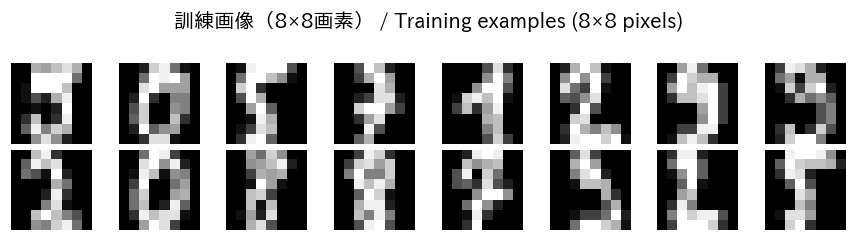

訓練数 / Train: 1437 | 評価数 / Held-out: 360


In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
raw = load_digits()
# sklearn同梱の8×8手書き数字．通信・認証は不要です． / Use the bundled sklearn 8×8 digits; no dataset download or authentication.
# 画像モデルの学習にクラスラベルは使いません．可視化だけに使います． / Class labels are used for visualization, not image-model training.
images = (raw.data / 16.0).astype('float32')
train_idx, test_idx = train_test_split(np.arange(len(images)), test_size=0.2,
                                    random_state=SEED, stratify=raw.target)
x_train = torch.tensor(images[train_idx])
x_test = torch.tensor(images[test_idx])
y_test = raw.target[test_idx]
loader = DataLoader(TensorDataset(x_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
def image_grid(x, title='', nrow=8):
    x = torch.as_tensor(x).detach().cpu().reshape(-1,8,8).numpy()
    rows = math.ceil(len(x)/nrow)
    fig, ax = plt.subplots(rows,nrow,figsize=(nrow,rows*1.1),squeeze=False)
    for a in ax.ravel(): a.axis('off')
    for a,im in zip(ax.ravel(),x): a.imshow(im,cmap='gray',vmin=0,vmax=1)
    fig.suptitle(title); plt.tight_layout(); plt.show()
image_grid(x_train[:16], '訓練画像（8×8画素） / Training examples (8×8 pixels)')
print('訓練数 / Train:',len(x_train),'| 評価数 / Held-out:',len(x_test))


## モデル / Model


In [ ]:
# 画像を[-1,1]へ変換．時刻インデックス0は数学的な最初のノイズ付加ステップに対応． / Scale images to [-1,1]; index 0 denotes the first forward noising step.
data=x_train.to(device)*2-1
betas=torch.linspace(.0001,.1,T,device=device)
alphas=1-betas
abar=torch.cumprod(alphas,dim=0)
abar_prev=torch.cat([torch.ones(1,device=device),abar[:-1]])
posterior_var=betas*(1-abar_prev)/(1-abar)
coef_x0=betas*abar_prev.sqrt()/(1-abar)
coef_xt=(1-abar_prev)*alphas.sqrt()/(1-abar)
print('最終時刻のalpha-bar / Terminal alpha-bar:',float(abar[-1]),'（小さいほど元信号が弱い / small: terminal signal is weak）')
def extract(v,t):return v[t].reshape(-1,1)
def q_sample(x0,t,eps=None):
    if eps is None:eps=torch.randn_like(x0)
    return extract(abar.sqrt(),t)*x0+extract((1-abar).sqrt(),t)*eps
class NoisePredictor(nn.Module):
    def __init__(self):
        super().__init__();self.register_buffer('freq',torch.exp(-math.log(10000)*torch.arange(16)/15))
        self.net=nn.Sequential(nn.Linear(64+32,HIDDEN),nn.SiLU(),nn.Linear(HIDDEN,HIDDEN),nn.SiLU(),nn.Linear(HIDDEN,HIDDEN),nn.SiLU(),nn.Linear(HIDDEN,64))
    def forward(self,x,t):
        phase=t.float()[:,None]*self.freq[None,:]
        emb=torch.cat([phase.sin(),phase.cos()],dim=1)
        return self.net(torch.cat([x,emb],dim=1))
model=NoisePredictor().to(device);optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
# EMAは生成のばらつきを抑えるための重み平均．追加の学習モデルではありません． / EMA averages model weights to stabilize sampling; it is not an additional trained model.
import copy
ema=copy.deepcopy(model).eval()
for p in ema.parameters():p.requires_grad_(False)


最終時刻のalpha-bar / Terminal alpha-bar: 0.005618758965283632 （小さいほど元信号が弱い / small: terminal signal is weak）


## 評価と可視化 / Evaluation and visualization


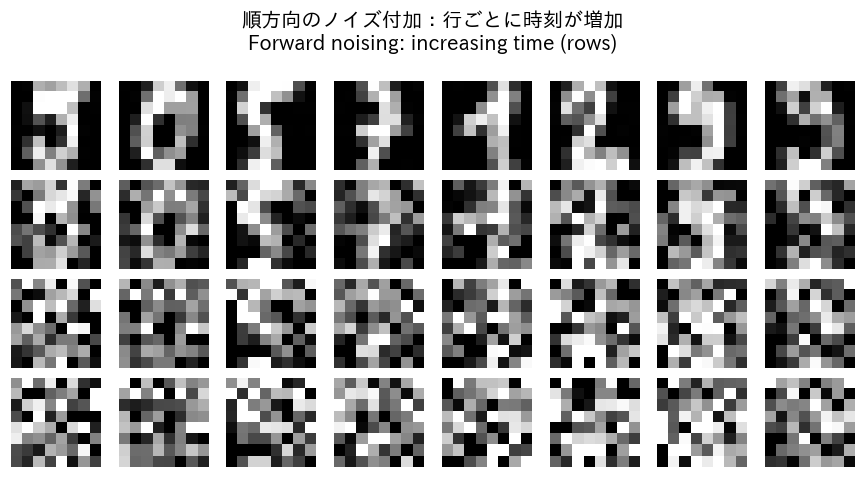

In [ ]:
# 元画像から選んだ時刻を直接作れます．ここでは視覚比較のため同じepsを使います． / Construct any selected time directly from x0; reuse eps here for visual comparison.
x0=data[:8];eps=torch.randn_like(x0)
levels=[0,T//4,T//2,T-1]
rows=[]
for level in levels:
    t=torch.full((len(x0),),level,device=device,dtype=torch.long)
    rows.append(((q_sample(x0,t,eps)+1)/2).clamp(0,1).cpu())
image_grid(torch.cat(rows),'順方向のノイズ付加：行ごとに時刻が増加\nForward noising: increasing time (rows)',nrow=8)


## 学習 / Training


ステップ / Step 1: ノイズMSE / noise MSE=1.0257
ステップ / Step 500: ノイズMSE / noise MSE=0.2179
ステップ / Step 1000: ノイズMSE / noise MSE=0.1898
ステップ / Step 1500: ノイズMSE / noise MSE=0.1848
ステップ / Step 2000: ノイズMSE / noise MSE=0.1996
ステップ / Step 2500: ノイズMSE / noise MSE=0.1767
ステップ / Step 3000: ノイズMSE / noise MSE=0.2178
ステップ / Step 3500: ノイズMSE / noise MSE=0.1939
経過時間 / Elapsed: 10.9s


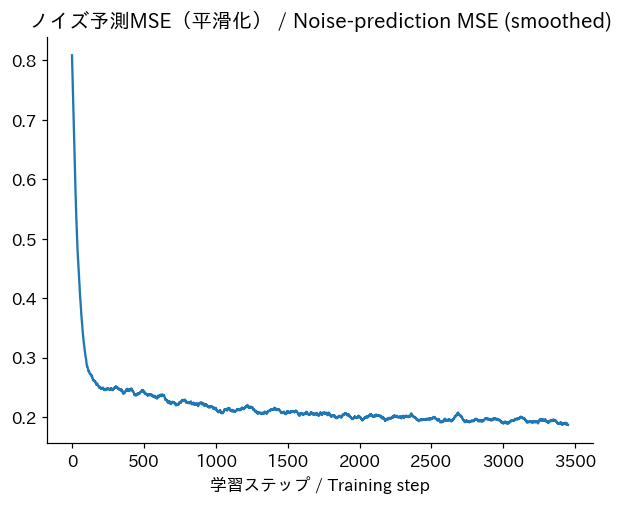

In [ ]:
history=[];start=time.time()
for step in range(TRAIN_STEPS):
    model.train();x0=data[torch.randint(len(data),(BATCH_SIZE,),device=device)]
    t=torch.randint(0,T,(len(x0),),device=device);eps=torch.randn_like(x0)
    xt=q_sample(x0,t,eps);optimizer.zero_grad();loss=F.mse_loss(model(xt,t),eps)
    loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
    with torch.no_grad():
        for pe,p in zip(ema.parameters(),model.parameters()):pe.mul_(.99).add_(p,alpha=.01)
    history.append(loss.item())
    if step==0 or (step+1)%500==0: print(f'ステップ / Step {step+1}: ノイズMSE / noise MSE={loss.item():.4f}')
print(f'経過時間 / Elapsed: {time.time()-start:.1f}s')
smooth=np.convolve(history,np.ones(min(50,len(history)))/min(50,len(history)),mode='valid')
plt.plot(smooth);plt.title('ノイズ予測MSE（平滑化） / Noise-prediction MSE (smoothed)');plt.xlabel('学習ステップ / Training step');plt.show()


## 評価と可視化 / Evaluation and visualization


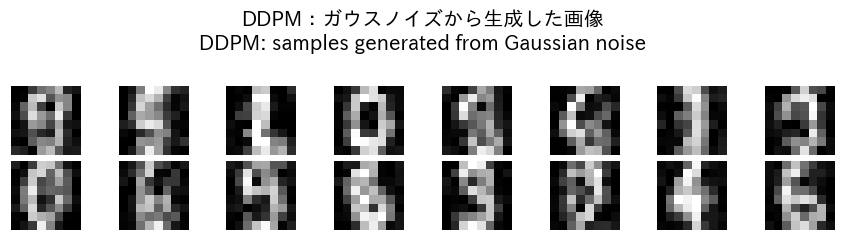

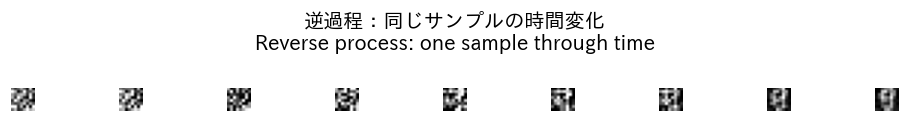

In [ ]:
@torch.no_grad()
def sample_ddpm(n=16,seed=9):
    ema.eval();generator=torch.Generator(device=device).manual_seed(seed)
    x=torch.randn((n,64),device=device,generator=generator)
    frames=[(T,x.cpu().clone())]
    record=set(np.linspace(0,T-1,8,dtype=int).tolist())
    for step in range(T-1,-1,-1):
        t=torch.full((n,),step,device=device,dtype=torch.long)
        eps=ema(x,t)
        # ノイズ予測からx0を推定し，DDPMのposterior平均に代入します． / Estimate x0 from predicted noise and substitute into the DDPM posterior mean.
        x0_hat=((x-extract((1-abar).sqrt(),t)*eps)/extract(abar.sqrt(),t)).clamp(-1,1)
        mean=extract(coef_x0,t)*x0_hat+extract(coef_xt,t)*x
        if step>0:
            noise=torch.randn(x.shape,device=device,generator=generator)
            x=mean+extract(posterior_var.sqrt(),t)*noise
        else:x=mean  # 最終ステップでは新たなノイズを加えません． / Do not add fresh noise at the final step.
        if step in record:frames.append((step,x.cpu().clone()))
    return ((x.cpu()+1)/2).clamp(0,1),frames
samples,reverse_frames=sample_ddpm(SAMPLE_COUNT)
image_grid(samples,'DDPM：ガウスノイズから生成した画像\nDDPM: samples generated from Gaussian noise')
image_grid(torch.stack([((x[0]+1)/2).clamp(0,1) for t,x in reverse_frames]),'逆過程：同じサンプルの時間変化\nReverse process: one sample through time',nrow=len(reverse_frames))


## インタラクティブ操作 / Interactive controls


In [ ]:
def show_reverse(index=0):
    step,x=reverse_frames[index];image_grid(((x+1)/2).clamp(0,1),f'逆過程・残り段階 / Reverse process | remaining step {step}')
widgets.interact(show_reverse,index=widgets.IntSlider(min=0,max=len(reverse_frames)-1,value=0,description='逆過程の段階 / Reverse step', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px'),continuous_update=False))


interactive(children=(IntSlider(value=0, continuous_update=False, description='逆過程の段階 / Reverse step', layout=…

<function __main__.show_reverse(index=0)>

## 観察・変更 / Observe and modify
- 既知のノイズと予測ノイズのMSEで学習し，生成時は元画像を与えていないことを確認する．
  Check that training minimizes MSE between known and predicted noise, while generation receives no original image.
- 逆過程の途中では新しい乱数を加え，最後は加えないことを確認する．
  Verify that fresh noise is added during intermediate reverse steps, but not at the final step.
- TRAIN_STEPSを増やし，ノイズ除去の過程と出力の変化を観察する．
  Increase TRAIN_STEPS and inspect changes in denoising trajectories and outputs.
- Tを変えるときは，最終alpha-barが十分小さいかも確認する．Tだけ減らすと事前分布との不一致が起こり得る．
  When changing T, check that the final alpha-bar remains sufficiently small. Reducing only T can create a mismatch with the prior.
- 表示のclampは可視化のためです．中間状態を画像範囲へ毎回切っているわけではありません（x0推定のclippingは行います）．
  Display clamping is for visualization. Intermediate states are not clipped to the image range at every step, although x0 estimates are clipped.
- サンプルの新規性・一般化は，生成されたように見えることだけでは保証されません．
  Generated appearance alone does not establish sample novelty or generalization.


## 参考 / References
- [DDPM original paper](https://arxiv.org/abs/2006.11239)
- [Author page and original implementation](https://hojonathanho.github.io/diffusion/)
